# `to_palabos`

Exports a porous medium image to a plain-text geometry file formatted for Palabos Lattice Boltzmann simulations, where voxels are labeled `0` (pore), `1` (solid-fluid interface), and `2` (interior solid).

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np

import porespy as ps

ps.visualization.set_mpl_style()

## `im` and `filename`

Generate a 3D binary image (`True` for pore, `False` for solid) and export it using `to_palabos`. We can read the exported text file back and reshape it to inspect the three Palabos voxel classes:

In [2]:
im = ps.generators.blobs(shape=[40, 40, 40], porosity=0.6, seed=0)

with tempfile.TemporaryDirectory() as tmpdir:
    fname = os.path.join(tmpdir, "geometry.dat")
    ps.io.to_palabos(im=im, filename=fname, solid=0)
    data = np.loadtxt(fname, dtype=int).reshape(im.shape)

for label, name in [(0, "Pore"), (1, "Interface"), (2, "Solid")]:
    print(f"{label} ({name:9s}): {np.sum(data == label):6d} voxels")

0 (Pore     ):  38400 voxels
1 (Interface):  25600 voxels
2 (Solid    ):      0 voxels


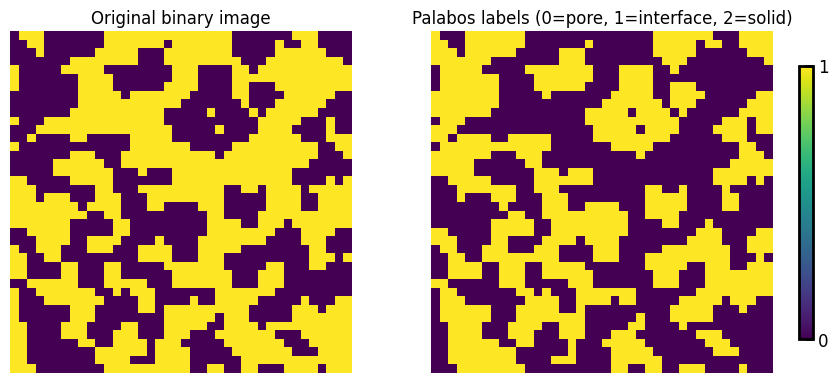

In [3]:
fig, ax = plt.subplots(1, 2, figsize=[10, 4])
ax[0].imshow(im[:, :, 20], origin="lower", interpolation="none")
ax[0].set_title("Original binary image")
ax[0].axis(False)

im1 = ax[1].imshow(data[:, :, 20], origin="lower", interpolation="none", cmap="viridis")
ax[1].set_title("Palabos labels (0=pore, 1=interface, 2=solid)")
ax[1].axis(False)
fig.colorbar(im1, ax=ax[1], ticks=[0, 1, 2], shrink=0.8);

## `solid`

If the input image uses a non-zero value to represent the solid phase (for example, `1` for solid and `0` for pore), specify `solid=1`:

In [4]:
im_inverted = (~im).astype(int)  # 1 = solid, 0 = pore

with tempfile.TemporaryDirectory() as tmpdir:
    fname = os.path.join(tmpdir, "geometry_solid1.dat")
    ps.io.to_palabos(im=im_inverted, filename=fname, solid=1)
    data_inv = np.loadtxt(fname, dtype=int).reshape(im.shape)

assert np.array_equal(data, data_inv)
print("Export with solid=1 matches original export identically.")

Export with solid=1 matches original export identically.
